Model Training
Import Data and Required Packages

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


In [11]:
import pandas as pd
df = pd.read_csv(r"C:\Users\harik\ml.project\ml_model\data\raw\StudentsPerformance.csv")
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
train_df = pd.read_csv(
    r"C:\Users\harik\ml.project\ml_model\data\processed\train_processed.csv"
)
test_df = pd.read_csv(
    r"C:\Users\harik\ml.project\ml_model\data\processed\test_processed.csv")


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [14]:
print(df.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')


In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Encode categorical columns
categorical_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,0,1,1,1,1,72,72,74
1,0,2,4,1,0,69,90,88
2,0,1,3,1,1,90,95,93
3,1,0,0,0,1,47,57,44
4,1,2,4,1,1,76,78,75


In [12]:
import pandas as pd
df = pd.read_csv(r"C:\Users\harik\ml.project\ml_model\data\raw\StudentsPerformance.csv")

In [6]:
print(df.columns)

print("Categories in race/ethnicity variable:",
      df['race/ethnicity'].unique())

print("Categories in parental level of education variable:",
      df['parental level of education'].unique())

print("Categories in lunch variable:",
      df['lunch'].unique())

print("Categories in test preparation course variable:",
      df['test preparation course'].unique())


Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')
Categories in race/ethnicity variable: ['group B' 'group C' 'group A' 'group D' 'group E']
Categories in parental level of education variable: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Categories in lunch variable: ['standard' 'free/reduced']
Categories in test preparation course variable: ['none' 'completed']


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2


In [13]:
X_train = train_df.drop('average_score', axis=1)
y_train = train_df['average_score']

X_test = test_df.drop('average_score', axis=1)
y_test = test_df['average_score']


NameError: name 'train_df' is not defined

In [16]:
X = df.drop(columns=['math score'])   # features
y = df['math score']                  # target
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in X.select_dtypes(include='object').columns:
    X[col] = le.fit_transform(X[col])


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [20]:
for i in range(len(list(models))):

    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(
        y_train, y_train_pred
    )

    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(
        y_test, y_test_pred
    )

    print(list(models.keys())[i])
    print("Train R2:", model_train_r2)
    print("Test R2:", model_test_r2)


Linear Regression
Train R2: 0.8615127758151003
Test R2: 0.8838026201112223
Decision Tree
Train R2: 0.9996534669718089
Test R2: 0.7498956186117769
Random Forest
Train R2: 0.9761927565190865
Test R2: 0.8487940184356789


In [18]:
model_list = []
r2_list = []

for i in range(len(list(models))):

    model = list(models.values())[i]

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluation
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(
        y_train, y_train_pred
    )

    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(
        y_test, y_test_pred
    )

    print("=" * 40)
    print(list(models.keys())[i])

    print("Model performance for Training set")
    print(f"- Mean Absolute Error: {model_train_mae:.4f}")
    print(f"- Root Mean Squared Error: {model_train_rmse:.4f}")
    print(f"- R2 Score: {model_train_r2:.4f}")

    print("\nModel performance for Test set")
    print(f"- Mean Absolute Error: {model_test_mae:.4f}")
    print(f"- Root Mean Squared Error: {model_test_rmse:.4f}")
    print(f"- R2 Score: {model_test_r2:.4f}")

    model_list.append(list(models.keys())[i])
    r2_list.append(model_test_r2)


Linear Regression
Model performance for Training set
- Mean Absolute Error: 4.4947
- Root Mean Squared Error: 5.5876
- R2 Score: 0.8615

Model performance for Test set
- Mean Absolute Error: 4.1301
- Root Mean Squared Error: 5.3175
- R2 Score: 0.8838
Decision Tree
Model performance for Training set
- Mean Absolute Error: 0.0187
- Root Mean Squared Error: 0.2795
- R2 Score: 0.9997

Model performance for Test set
- Mean Absolute Error: 6.0000
- Root Mean Squared Error: 7.8013
- R2 Score: 0.7499
Random Forest
Model performance for Training set
- Mean Absolute Error: 1.8508
- Root Mean Squared Error: 2.3167
- R2 Score: 0.9762

Model performance for Test set
- Mean Absolute Error: 4.7008
- Root Mean Squared Error: 6.0658
- R2 Score: 0.8488


In [23]:
# Linear models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Neighbors
from sklearn.neighbors import KNeighborsRegressor

# Tree-based models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor

# Support Vector Machine
from sklearn.svm import SVR


In [24]:
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


In [26]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "AdaBoost": AdaBoostRegressor(),
    "SVR": SVR(),
    "XGBoost": XGBRegressor(),
    "CatBoost": CatBoostRegressor(verbose=0)
}
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    return mae, rmse, r2


In [27]:
results = []

for name, model in models.items():
    mae, rmse, r2 = evaluate_model(
        model, X_train, y_train, X_test, y_test
    )
    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2 Score"]
)

results_df.sort_values(by="R2 Score", ascending=False)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.130145,5.317451,0.883803
1,Ridge Regression,4.131050,5.319494,0.883713
9,CatBoost,4.639908,6.059754,0.849097
6,AdaBoost,4.724277,6.086018,0.847786
5,Random Forest,4.763421,6.087707,0.847701
2,Lasso Regression,4.983075,6.319629,0.835876
8,XGBoost,5.106823,6.527363,0.824909
4,Decision Tree,6.115000,8.004061,0.736725
3,KNN,7.443000,9.068815,0.662020
7,SVR,7.712086,9.613859,0.620174


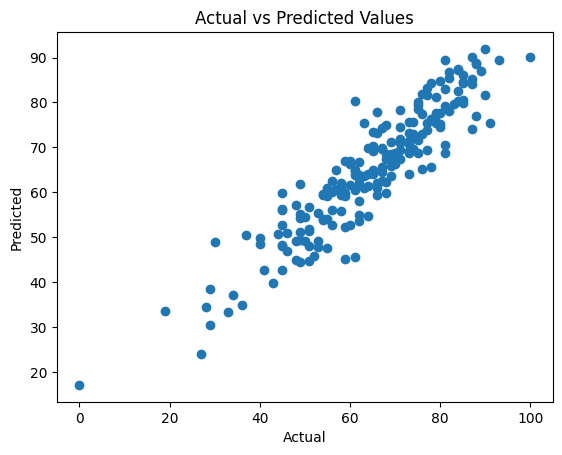

In [28]:

import matplotlib.pyplot as plt

# Make sure y_pred is defined
y_pred = model.predict(X_test)

plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted Values")
plt.show()


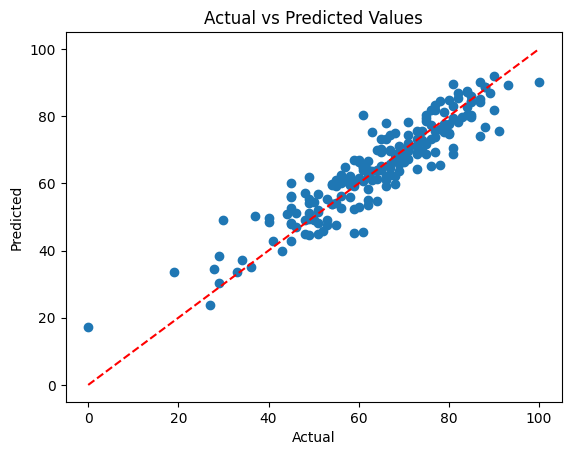

In [29]:
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], '--r')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted Values")
plt.show()


In [30]:
import pandas as pd

# Make sure y_pred is already created
y_pred = model.predict(X_test)

pred_df = pd.DataFrame({
    "Actual Value": y_test,
    "Predicted Value": y_pred,
    "Difference": y_test - y_pred
})

pred_df.head()


,Actual Value,Predicted Value,Difference
521,91,75.523786,15.476214
737,53,55.330069,-2.330069
740,80,77.678333,2.321667
660,74,75.633957,-1.633957
411,84,87.311135,-3.311135
